In [1]:
import camb
import matplotlib.pyplot as plt
import numpy as np
import os
import yaml

import numcosmo_II as nc

from classy import Class
from datetime import datetime
from pathlib import Path
from scipy.special import spherical_jn

## Initial Configurations

In [2]:
current_dir  = Path.cwd()
project_root = current_dir.parent if current_dir.name == 'analysis' else current_dir
yaml_path = project_root / 'config' / "setup.yaml"

print( 100 * "=" )
print( "Loading Initial Setup" )
print( f"Project root set as: {project_root}" )
print( 100 * "=" + "\n" )

with open(yaml_path, "r", encoding = "utf-8" ) as config_file:
    config = yaml.safe_load( config_file )

print(f"{yaml.dump( config, sort_keys = False, allow_unicode = True ) }")

config_out   = config[ "output" ]
output_dir   = project_root / config_out["root"]
os.makedirs(output_dir, exist_ok=True)

timestamp     = datetime.now().strftime( "%Y%m%d_%H%M%S" )
base_filename = f"{config_out[ 'base_name' ]}_{timestamp}"
output_base   = output_dir / base_filename

Loading Initial Setup
Project root set as: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II

cosmology:
  h: 0.6737
  Omega_b: 0.0493
  Omega_cdm: 0.2657
  Omega_m: 0.315
  Omega_r: 0.0
  Omega_lambda: 0.685
  w0_fld: -1.0
  wa_fld: 0.0
primordial:
  A_s: 2.1e-09
  n_s: 0.9649
  k_pivot: 0.05
growth:
  a_i: 0.0001
  a_f: 1.0
  num_points: 400
  solver:
    rtol: 1.0e-08
    atol: 1.0e-10
spt:
  box_size_L: 500.0
  grid_Ng: 128
  scale_factor_aref: 1.0
  pk_num_bins: 20
  bispectrum_num_bins: 12
  skewness:
    R_min: 4.0
    R_max: 12.0
    num_radii: 9
ensemble:
  num_realizations: 25
  seed_start: 12345
boltzmann:
  default_solver: class
  z_output: 0.0
  non_linear: none
  gauge: newtonian
  k_sampling:
    k_min: 0.0001
    k_max: 10.0
    num_points: 200
  precision_test:
    rtol: 1.0e-08
    atol: 1.0e-10
    k_per_decade_for_pk: 100
superhorizon_potential:
  y_i: 0.0001
  y_f: 1.0e3
  solver:
    rtol: 1.0e-10
    atol: 1.0e-12
output:
  root: a

In [3]:
# _____ Cosmological Models & Parameters _____ #

cosmo_params = config[ "cosmology" ]
flrw_keys    = [ "h", "Omega_m", "Omega_r", "Omega_lambda", "w0_fld", "wa_fld" ]
flrw_params  = { k: cosmo_params[ k ] for k in flrw_keys if k in cosmo_params }

lcdm_model = nc.FLRW( **flrw_params )

eds_params = flrw_params.copy()
eds_params.update( {"Omega_m": 1.0, "Omega_lambda": 0.0, "Omega_r": 0.0} )
eds_model  = nc.FLRW( **eds_params )

ocdm_params = flrw_params.copy()
ocdm_params.update( {"Omega_m": flrw_params[ "Omega_m" ], "Omega_lambda": 0.0, "Omega_r": 0.0} )
ocdm_model  = nc.FLRW( **ocdm_params )

# _____ Primordial Spectrum Configuration _____ #

primordial_cfg = config[ "primordial" ]
A_s            = primordial_cfg[ "A_s" ]
n_s            = primordial_cfg[ "n_s" ]
k_pivot        = primordial_cfg[ "k_pivot" ]

In [4]:
# _____ Linear Growth Parameters _____ #

a_i = config[ "growth" ][ "a_i" ]
a_f = config[ "growth" ][ "a_f" ]

N_span = [ np.log( a_i ), np.log( a_f ) ]
N_eval = np.linspace( N_span[0], N_span[ 1 ], config[ "growth" ][ "num_points" ] )
a_eval = np.exp (N_eval )

growth_solver_opts = config[ "growth" ][ "solver" ]

# _____ SPT Field & Ensemble Configurations _____ #

spt_cfg = config[ "spt" ]
gf = nc.GaussianField(
    L    = spt_cfg[ "box_size_L" ],
    Ng   = spt_cfg[ "grid_Ng" ],
    aref = spt_cfg[ "scale_factor_aref" ]
)

spt       = nc.SPTStatistics(gf)
ensem_cfg = config[ "ensemble" ]


In [5]:
# _____ Boltzmann Solver Configurations _____ #

boltzmann_cfg  = config[ "boltzmann" ]
default_solver = boltzmann_cfg[ "default_solver" ]
z_output       = boltzmann_cfg[ "z_output" ]
gauge          = boltzmann_cfg[ "gauge" ]

k_samp_cfg   = boltzmann_cfg[ "k_sampling" ]
k_min        = k_samp_cfg[ "k_min" ]
k_max        = k_samp_cfg[ "k_max" ]
k_num_points = k_samp_cfg[ "num_points" ]

boltzmann_prec_opts = boltzmann_cfg[ "precision_test" ]

# _____ Superhorizon Potential Configuration _____ #

superhorizon_cfg = config[ "superhorizon_potential" ]

y_i                      = superhorizon_cfg[ "y_i" ]
y_f                      = superhorizon_cfg[ "y_f" ]
superhorizon_solver_opts = superhorizon_cfg[ "solver" ]

## Cosmological Analysis and Tests (Ex 1)

### $D(a)$ and $f(a)$ Validation

In [6]:
sol_eds  = eds_model.solve_growth(  N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)
sol_lcdm = lcdm_model.solve_growth( N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)
sol_ocdm = ocdm_model.solve_growth( N = N_span, y0 = [ a_i, a_i ], **growth_solver_opts)

In [7]:
D_eds,  f_eds  = eds_model.get_growth_observables(  sol_eds,  N_eval = N_eval )
D_lcdm, f_lcdm = lcdm_model.get_growth_observables( sol_lcdm, N_eval = N_eval )
D_ocdm, f_ocdm = ocdm_model.get_growth_observables( sol_ocdm, N_eval = N_eval )

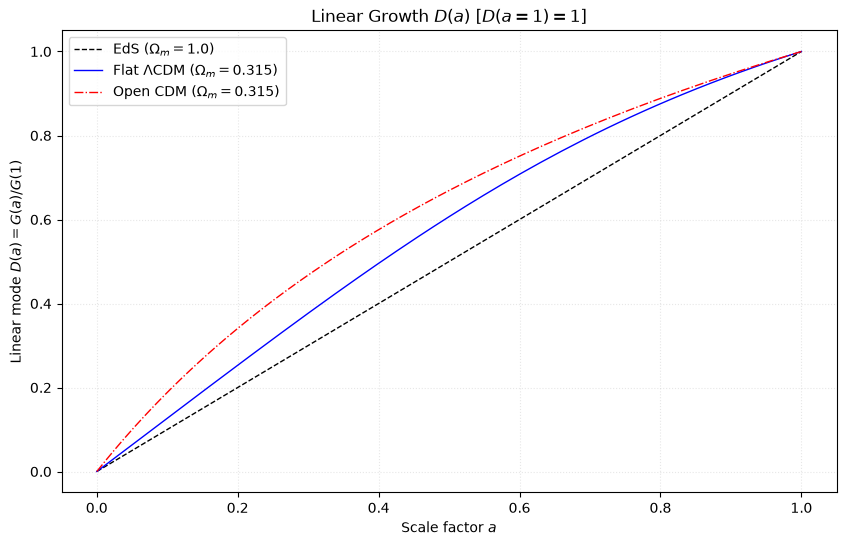

Linear Growth plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261013_190209_linear_growth.png



In [8]:
plt.figure( figsize = ( 10, 6 ) )

plt.plot( a_eval, D_eds,  'k--', lw = 1, label = r'EdS ($\Omega_m=1.0$)' )
plt.plot( a_eval, D_lcdm, 'b-',  lw = 1, label = rf'Flat $\Lambda$CDM ($\Omega_m={lcdm_model.O_matter:.3f}$)' )
plt.plot( a_eval, D_ocdm, 'r-.', lw = 1, label = rf'Open CDM ($\Omega_m={ocdm_model.O_matter:.3f}$)' )

plt.xlabel( r'Scale factor $a$' )
plt.ylabel( r'Linear mode $D(a) = G(a)/G(1)$' )

plt.title( r'Linear Growth $D(a)$ [$D(a=1)=1$]' )

plt.grid( True, ls = ':', alpha = 0.3 )
plt.legend()


linear_growth_path = f"{output_base}_linear_growth.png"
plt.savefig( linear_growth_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Growth plot saved to: {linear_growth_path}\n" )

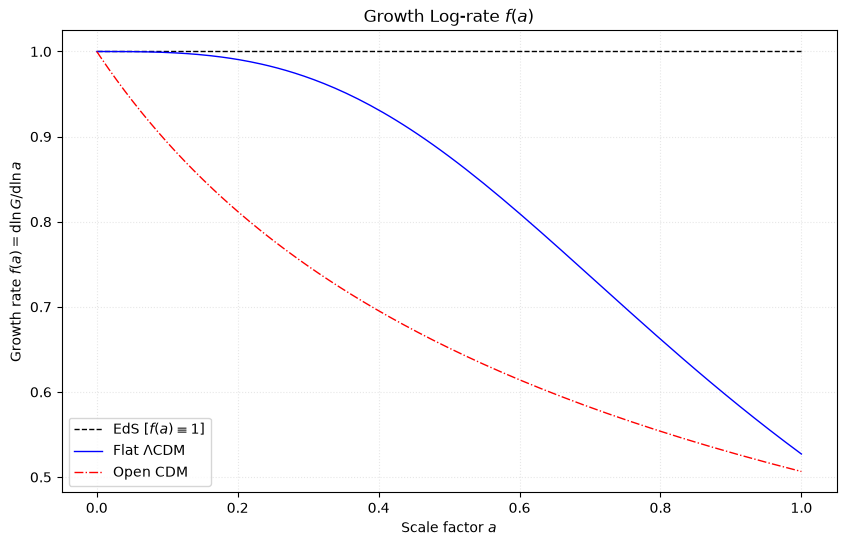

Linear Growth plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261013_190209_growth_rate.png



In [9]:
plt.figure( figsize = ( 10, 6 ) )

plt.plot( a_eval, f_eds,  'k--', lw = 1, label = r'EdS [$f(a) \equiv 1$]' )
plt.plot( a_eval, f_lcdm, 'b-',  lw = 1, label = r'Flat $\Lambda$CDM' )
plt.plot( a_eval, f_ocdm, 'r-.', lw = 1, label = r'Open CDM' )

plt.xlabel( r'Scale factor $a$' )
plt.ylabel( r'Growth rate $f(a) = \mathrm{d}\ln G / \mathrm{d}\ln a$' )

plt.title( r'Growth Log-rate $f(a)$' )

plt.grid( True, ls=':', alpha = 0.3 )
plt.legend()

growth_rate_path = f"{output_base}_growth_rate.png"
plt.savefig( growth_rate_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Growth plot saved to: {growth_rate_path}\n" )

In [10]:
print( f"EdS (a=1):  D = {D_eds[-1]:.6f} (expected 1.0) | f = {f_eds[-1]:.6f} (expected 1.0)" )
print( f"LCDM (a=1): D = {D_lcdm[-1]:.6f} | f = {f_lcdm[-1]:.6f}" )
print( f"OCDM (a=1): D = {D_ocdm[-1]:.6f} | f = {f_ocdm[-1]:.6f}" )

EdS (a=1):  D = 1.000000 (expected 1.0) | f = 1.000000 (expected 1.0)
LCDM (a=1): D = 1.000000 | f = 0.527103
OCDM (a=1): D = 1.000000 | f = 0.506548


### Quadrature vs ODE

In [11]:
a_test      = np.linspace( 0.05, 1.0, 25 )
G_ode_vals  = [ sol_lcdm.sol( np.log( a_v ) )[ 0 ] for a_v in a_test ]
G_quad_vals = [ lcdm_model.growth_quadrature( a_v ) for a_v in a_test ]

err_rel = np.abs( np.array( G_ode_vals ) - np.array( G_quad_vals ) ) / np.array( G_quad_vals )
print(f"Maximum relative error: {np.max(err_rel):.3e}")

Maximum relative error: 2.124e-07


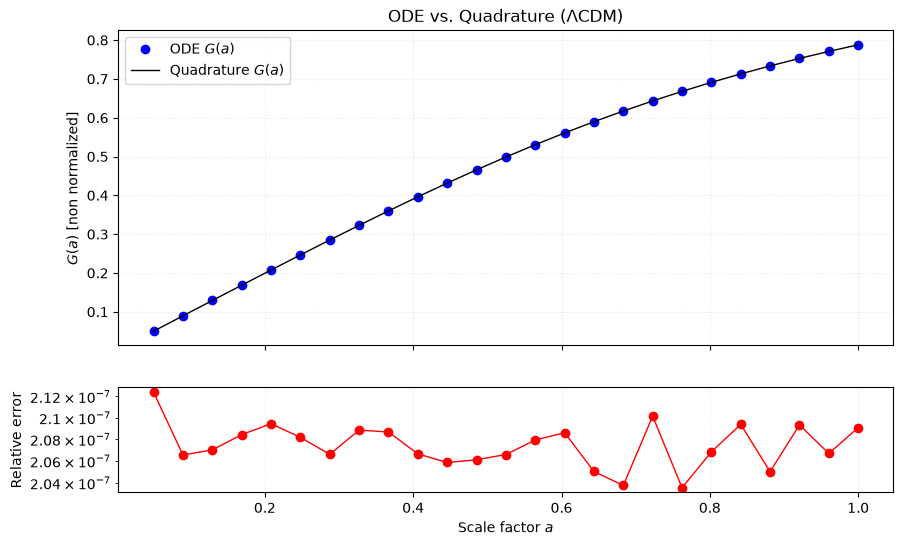

Linear Growth plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261013_190209_quadrature_ODE_validation.png



In [12]:
fig, ( ax1, ax2 ) = plt.subplots( 2, 1, figsize = ( 10, 6 ), sharex = True, gridspec_kw = {'height_ratios': [ 3, 1 ]} )

ax1.plot( a_test, G_ode_vals,  'bo', label = r'ODE $G(a)$' )
ax1.plot( a_test, G_quad_vals, 'k-', lw = 1, label = r'Quadrature $G(a)$' )

ax1.set_ylabel( r'$G(a)$ [non normalized]' )
ax1.set_title( r'ODE vs. Quadrature ($\Lambda\mathrm{CDM}$)' )

ax1.legend()
ax1.grid( True, ls=':', alpha = 0.3)

ax2.plot( a_test, err_rel, 'r-o', lw = 1 )
ax2.set_yscale( 'log' )
ax2.set_xlabel( r'Scale factor $a$' )
ax2.set_ylabel( r'Relative error' )
ax2.grid( True, ls=':', alpha = 0.3 )

quadrature_ODE_validation_path = f"{output_base}_quadrature_ODE_validation.png"
plt.savefig( quadrature_ODE_validation_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Growth plot saved to: {quadrature_ODE_validation_path}\n" )

### Initial Conditions Sensibility

In [13]:
a_i_list = [ 1e-3, 1e-4, 1e-5 ]
tol_list = [ ( 1e-6, 1e-8 ), ( 1e-8, 1e-10 ), ( 1e-10, 1e-12 ) ]

print( "=" * 100 )
print( f"{'a_i':<10} | {'rtol, atol':<20} | {'f(a=1)':<14} | {'D(a=1)':<14} | {'Erro Rel. f in a=1':<20}" )
print( "=" * 100 )

f_ref = None

for a_init in a_i_list:
    for rtol, atol in tol_list:
        sol_t = lcdm_model.solve_growth(
            N = [ np.log( a_init ), 0.0 ], y0 = [ a_init, a_init ], rtol = rtol, atol = atol
        )
        D_t, f_t = lcdm_model.get_growth_observables( sol_t, N_eval = [ 0.0 ] )
        
        if f_ref is None:
            f_ref = f_t[ 0 ]
            diff  = 0.0
        else:
            diff = abs( f_t[0] - f_ref ) / f_ref

        print( f"{a_init:<10.1e} | {str((rtol, atol)):<20} | {f_t[0]:<14.8f} | {D_t[0]:<14.8f} | {diff:<20.2e}" )
print("=" * 100)

a_i        | rtol, atol           | f(a=1)         | D(a=1)         | Erro Rel. f in a=1  
1.0e-03    | (1e-06, 1e-08)       | 0.52710275     | 1.00000000     | 0.00e+00            
1.0e-03    | (1e-08, 1e-10)       | 0.52710320     | 1.00000000     | 8.54e-07            
1.0e-03    | (1e-10, 1e-12)       | 0.52710320     | 1.00000000     | 8.62e-07            
1.0e-04    | (1e-06, 1e-08)       | 0.52710281     | 1.00000000     | 1.24e-07            
1.0e-04    | (1e-08, 1e-10)       | 0.52710320     | 1.00000000     | 8.54e-07            
1.0e-04    | (1e-10, 1e-12)       | 0.52710320     | 1.00000000     | 8.62e-07            
1.0e-05    | (1e-06, 1e-08)       | 0.52710276     | 1.00000000     | 2.71e-08            
1.0e-05    | (1e-08, 1e-10)       | 0.52710320     | 1.00000000     | 8.54e-07            
1.0e-05    | (1e-10, 1e-12)       | 0.52710320     | 1.00000000     | 8.62e-07            


## SPT and Mode Coupling (Ex 2)

In [14]:
gf.P_linear = lambda k, a = 1.0: np.where( k == 0, 0.0, 10.0 * ( k / 0.1 ) * np.exp( -( k / 0.8 ) ** 2 ) )

delta_1_x, delta_1_k = gf.Gaussian_field()

delta_2_x, delta_2_k = spt.compute_delta_2( delta_1_k )

delta_tot_k = delta_1_k + delta_2_k
delta_tot_x = delta_1_x + delta_2_x

k_p, P_1, n_modes = spt.spt_power_spectrum( delta_1_k,   num_bins = spt_cfg[ 'pk_num_bins' ] )
_, P_tot, _       = spt.spt_power_spectrum( delta_tot_k, num_bins = spt_cfg[ 'pk_num_bins' ] )

print(f"Linear variance: sigma_1^2 = {np.var(delta_1_x):.4e}")
print(f"Total variance:  sigma_tot^2 = {np.var(delta_tot_x):.4e}")

Linear variance: sigma_1^2 = 4.6104e-01
Total variance:  sigma_tot^2 = 9.2059e-01


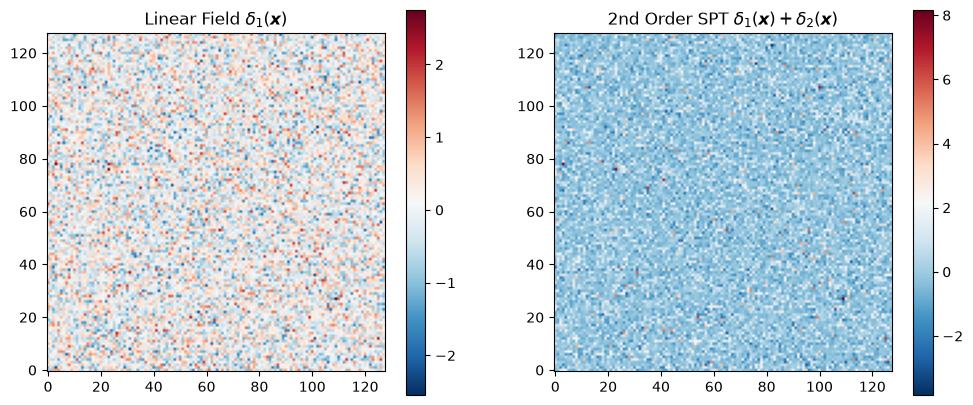

Linear Vs 2nd Order SPT plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261013_190209_Linear_Vs_2ndO_SPT.png



In [15]:
fig = plt.figure( figsize = ( 12, 5 ) )

ax1 = fig.add_subplot( 1, 2, 1 )
im1 = ax1.imshow(delta_1_x[ :, :, 0 ], cmap = 'RdBu_r', origin = 'lower')

ax1.set_title( r'Linear Field $\delta_1(\boldsymbol{x})$' )
plt.colorbar( im1, ax = ax1)

ax2 = fig.add_subplot( 1, 2, 2 )
im2 = ax2.imshow( delta_tot_x[ :, :, 0 ], cmap ='RdBu_r', origin = 'lower' )
ax2.set_title( r'2nd Order SPT $\delta_1(\boldsymbol{x}) + \delta_2(\boldsymbol{x})$' )
plt.colorbar( im2, ax = ax2 )

Linear_Vs_2ndO_SPT_path = f"{output_base}_Linear_Vs_2ndO_SPT.png"
plt.savefig( Linear_Vs_2ndO_SPT_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Linear Vs 2nd Order SPT plot saved to: {Linear_Vs_2ndO_SPT_path}\n" )


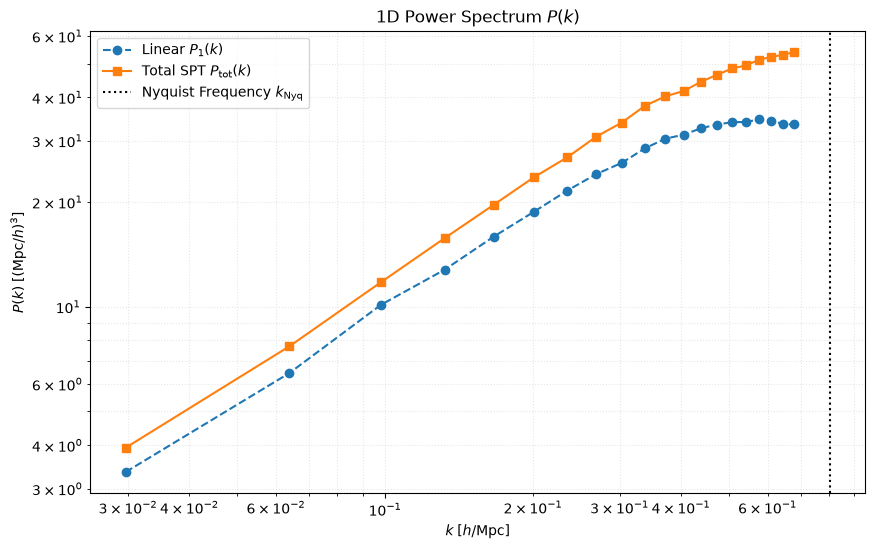

1D Power Spectrum plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261013_190209_Pk_1D_comparison.png



In [16]:
plt.figure( figsize = ( 10, 6 ) )

plt.plot(k_p, P_1,   'o--', label = r'Linear $P_1(k)$' )
plt.plot(k_p, P_tot, 's-',  label = r'Total SPT $P_{\mathrm{tot}}(k)$' )

plt.axvline( np.pi * gf.Ng / gf.L, color='k', ls=':', label = r'Nyquist Frequency $k_{\mathrm{Nyq}}$')
plt.xscale( 'log' )
plt.yscale( 'log' )

plt.xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
plt.ylabel(r'$P(k) \; [(\mathrm{Mpc}/h)^3]$' )

plt.title( r'1D Power Spectrum $P(k)$' )

plt.grid( True, which = "both", ls = ":", alpha = 0.3 )
plt.legend()

Pk_1D_path = f"{output_base}_Pk_1D_comparison.png"
plt.savefig( Pk_1D_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"1D Power Spectrum plot saved to: {Pk_1D_path}\n" )

In [17]:
gf.P_linear = lambda k, a = 1.0: np.where( k == 0, 0.0, 0.1 * ( k / 0.1 ) * np.exp( - (k / 0.8 ) ** 2 ) )

delta_1_x, delta_1_k = gf.Gaussian_field()
delta_2_x, delta_2_k = spt.compute_delta_2( delta_1_k )

delta_tot_k = delta_1_k + delta_2_k
delta_tot_x = delta_1_x + delta_2_x

print( f"Linear variance sigma_1^2 = {np.var( delta_1_x ):.4e}" )

k_b, B_meas, B_tree = spt.spt_equilateral_bispectrum(
    delta_tot_k, num_bins = spt_cfg[ 'bispectrum_num_bins' ]
)

R_array = np.linspace( 4.0, 12.0, 8 )
_, S3_vals = spt.spt_S3_profile( delta_tot_x, R_array )

Linear variance sigma_1^2 = 4.5981e-03


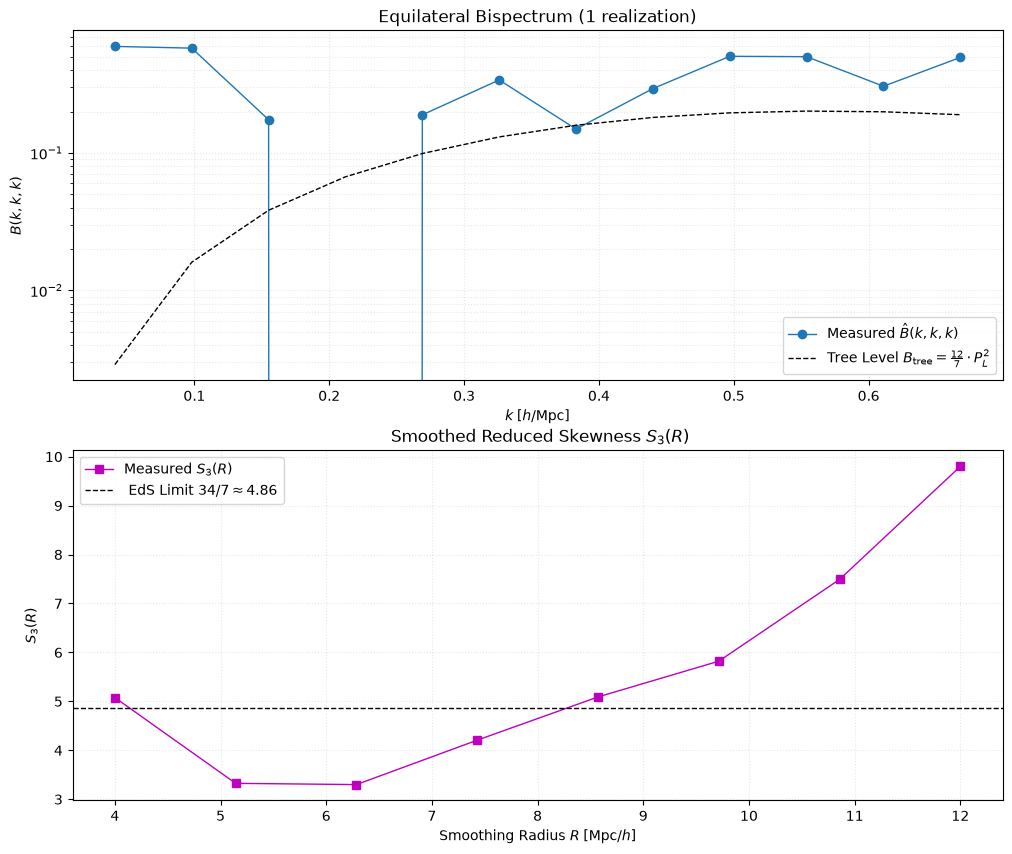

Bispectrum and S_3(R) single realization plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261013_190209_Bispectrum_S3R_1rea.png



In [18]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot( k_b, B_meas, 'o-',  lw = 1, label = r'Measured $\hat{B}(k,k,k)$')
axes[0].plot( k_b, B_tree, 'k--', lw = 1, label = r'Tree Level $B_{\mathrm{tree}} = \frac{12}{7}\cdot P_L^2$')

axes[0].set_yscale( 'log' )
axes[0].set_xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
axes[0].set_ylabel( r'$B(k,k,k)$' )

axes[0].set_title( r'Equilateral Bispectrum (1 realization)' )
axes[0].grid( True, which = "both", ls = ":", alpha = 0.3 )
axes[0].legend()


axes[1].plot( R_array, S3_vals, 's-m', lw=1, label = r'Measured $S_3(R)$' )
axes[1].axhline( 34.0/7.0, color = 'k', linestyle='--', lw = 1, label = r' EdS Limit $34/7 \approx 4.86$' )

axes[1].set_xlabel( r'Smoothing Radius $R \; [\mathrm{Mpc}/h]$' )
axes[1].set_ylabel( r'$S_3(R)$' )
axes[1].set_title( r' Smoothed Reduced Skewness $S_3(R)$')
axes[1].grid( True, ls = ":", alpha = 0.3 )
axes[1].legend()

Bispectrum_S3R_1rea_path = f"{output_base}_Bispectrum_S3R_1rea.png"
plt.savefig( Bispectrum_S3R_1rea_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Bispectrum and S_3(R) single realization plot saved to: {Bispectrum_S3R_1rea_path}\n" )


In [19]:
ensemble_res = spt.run_ensemble_analysis(
    num_realizations = ensem_cfg[ 'num_realizations' ],
    num_bins         = spt_cfg[ 'bispectrum_num_bins' ],
    R_array          = np.linspace( 4.0, 10.0, 7 )
)

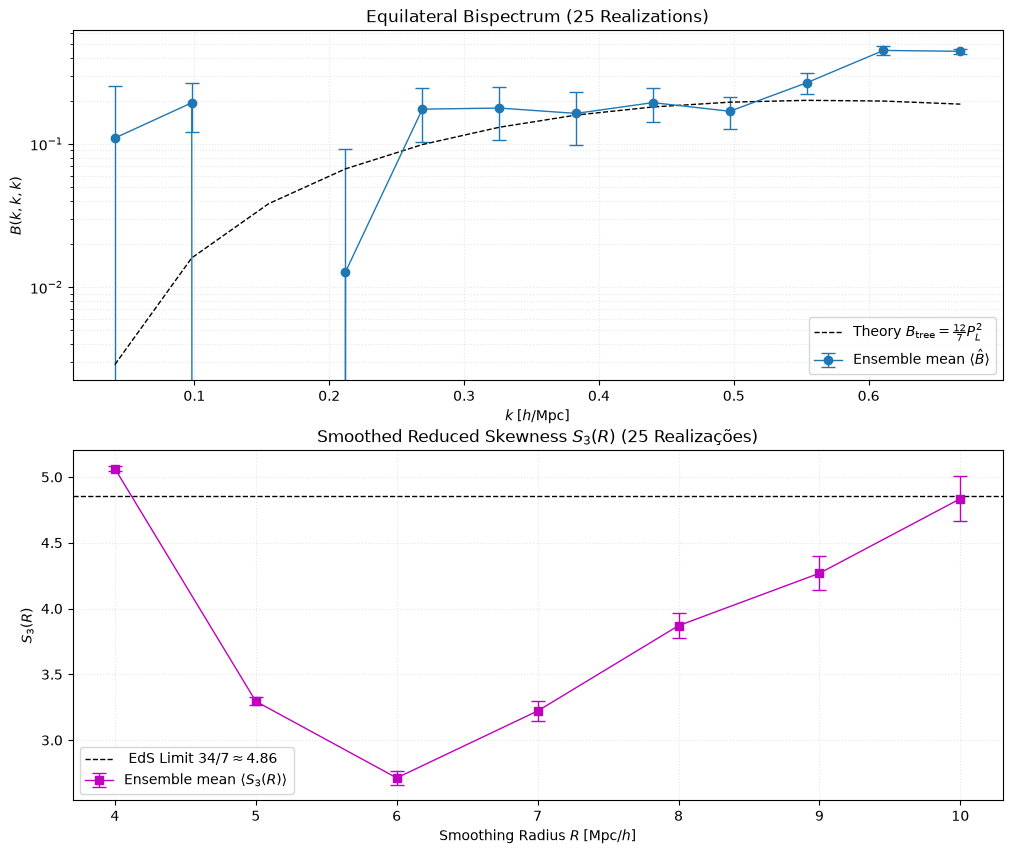

Bispectrum and S_3(R) ensemble realization plot saved to: /home/alex/Área de trabalho/Pós-Graduação/Disciplinas/Numerical_Cosmology_1/EP_II/analysis/output/Test_20261013_190209_Bispectrum_S3R_ensemble.png



In [20]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].errorbar(
    ensemble_res[ "k_b" ], ensemble_res[ "B_mean" ], yerr = ensemble_res[ "B_std" ],
    fmt = 'o-', capsize = 5, lw = 1, label = r'Ensemble mean $\langle \hat{B} \rangle$'
)

axes[0].plot(
    ensemble_res[ "k_b" ], ensemble_res["B_tree"], 'k--', lw = 1,
    label = r'Theory $B_{\mathrm{tree}} = \frac{12}{7}P_L^2$'
)

axes[0].set_yscale( 'log' )
axes[0].set_xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
axes[0].set_ylabel( r'$B(k,k,k)$' )
axes[0].set_title(rf'Equilateral Bispectrum ({ensem_cfg["num_realizations"]} Realizations)')
axes[0].grid( True, which = "both", ls = ":", alpha = 0.3 )
axes[0].legend()

axes[1].errorbar(
    ensemble_res[ "R_array" ], ensemble_res[ "S3_mean" ], yerr = ensemble_res[ "S3_std" ],
    fmt = 's-m', capsize = 5, lw = 1, label = r'Ensemble mean $\langle S_3(R) \rangle$'
)
axes[1].axhline( 34.0/7.0, color = 'k', linestyle='--', lw = 1, label = r' EdS Limit $34/7 \approx 4.86$' )

axes[1].set_xlabel( r'Smoothing Radius $R \; [\mathrm{Mpc}/h]$' )
axes[1].set_ylabel( r'$S_3(R)$' )

axes[1].set_title( rf'Smoothed Reduced Skewness $S_3(R)$ ({ensem_cfg[ "num_realizations" ]} Realizações)' )
axes[1].grid( True, ls = ":", alpha = 0.3 )
axes[1].legend()

Bispectrum_S3R_ensemble_path = f"{output_base}_Bispectrum_S3R_ensemble.png"
plt.savefig( Bispectrum_S3R_ensemble_path, dpi = 300, bbox_inches = "tight" )
#plt.close()
plt.show()
print( f"Bispectrum and S_3(R) ensemble realization plot saved to: {Bispectrum_S3R_ensemble_path}\n" )


## Bolztmann Solvers (Ex 5)

### Matter Power Spectrum Reconstruction (CLASS)

In [21]:
h         = cosmo_params[ "h" ]
Omega_b   = cosmo_params[ "Omega_b" ]
Omega_cdm = cosmo_params[ "Omega_cdm" ]
Omega_m   = cosmo_params[ "Omega_m" ]

In [22]:
validator = nc.boltzmann_map.BoltzmannMapValidator(
    fiducial_params = {
    'h': h, 'omega_b': Omega_b * ( h ** 2 ), 'omega_cdm': Omega_cdm * ( h ** 2 ), 'A_s': A_s, 'n_s': n_s, 'k_pivot': k_pivot, 'z': z_output 
    })

cosmo = Class()
cosmo.set(
    {'h': h, 'omega_b': Omega_b * ( h ** 2 ), 'omega_cdm': Omega_cdm * ( h ** 2 ), 'A_s': A_s, 'n_s': n_s, 'k_pivot': k_pivot,
    'output': 'mPk, mTk', 'z_pk': z_output, 'gauge': gauge, 'P_k_max_h/Mpc': k_max, 'non linear': 'none'
    })

cosmo.compute()

In [23]:
k_h   = np.logspace( np.log10( k_min ), np.log10( k_max ), k_num_points ) 
k_mpc = k_h * h                                                   

pk_class_mpc = np.array( [ cosmo.pk_lin( k_val, z_output ) for k_val in k_mpc ] )
pk_class_h   = pk_class_mpc * ( h ** 3 )                                         


tk_dict = cosmo.get_transfer( z_output )
k_tk    = tk_dict[ 'k (h/Mpc)' ] 

if 'd_m' in tk_dict:
    T_m_raw = tk_dict[ 'd_m' ]
else:
    T_m_raw = ( Omega_b * tk_dict[ 'd_b' ] + Omega_cdm * tk_dict[ 'd_cdm' ] ) / Omega_m

T_m_raw_rec = 1.5 * T_m_raw

T_m_interp = np.interp( k_mpc, k_tk, T_m_raw_rec )


pk_rec_mpc = validator.rec_matter_power_spectrum( k_mpc, T_m_interp )
pk_rec_h   = pk_rec_mpc * ( h ** 3 )

residual = ( pk_rec_mpc - pk_class_mpc ) / pk_class_mpc

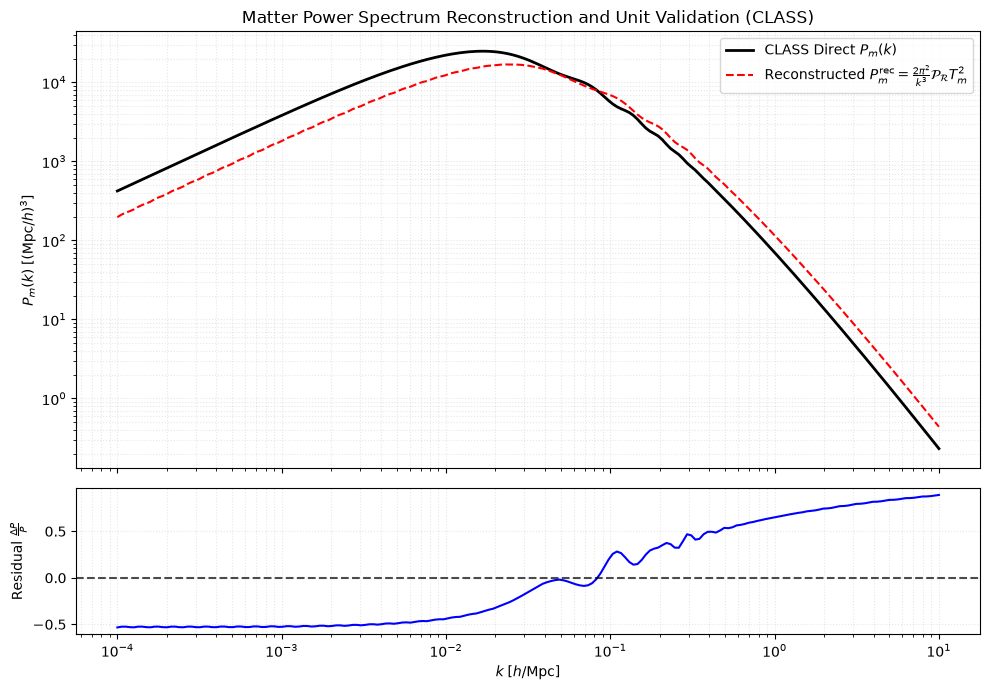

In [27]:
fig, axes = plt.subplots( 2, 1, figsize = ( 10, 7 ), sharex = True, gridspec_kw = {'height_ratios': [ 3, 1 ]} )

axes[0].plot( k_h, pk_class_h, 'k-',  lw =2,    label = r'CLASS Direct $P_m(k)$' )
axes[0].plot( k_h, pk_rec_h,   'r--', lw = 1.5, label = r'Reconstructed $P_m^{\mathrm{rec}} = \frac{2\pi^2}{k^3} \mathcal{P}_{\mathcal{R}} T_m^2$' )

axes[0].set_xscale( 'log' )
axes[0].set_yscale( 'log' )
axes[0].set_ylabel( r'$P_m(k) \; [(\mathrm{Mpc}/h)^3]$' )
axes[0].set_title( 'Matter Power Spectrum Reconstruction and Unit Validation (CLASS)')
axes[0].grid( True, which = "both", ls = ":", alpha = 0.3 )
axes[0].legend()

axes[1].plot( k_h, residual, 'b-' )
axes[1].axhline( 0, color = 'k', linestyle = '--', alpha = 0.7 )
axes[1].set_xscale( 'log')
axes[1].set_xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
axes[1].set_ylabel( r'Residual $\frac{\Delta P}{P}$' )
axes[1].grid( True, which = "both", ls = ":", alpha = 0.3 ) 

plt.tight_layout()
plt.savefig( f"{output_base}_Pm_reconstruction.png", dpi = 300, bbox_inches = "tight" ) 
plt.show()

cosmo.struct_cleanup()
cosmo.empty()

### Precision and Convergence Test

In [28]:
cosmo_def = Class()
cosmo_def.set(
    {'h': h, 'omega_b': Omega_b * ( h ** 2 ), 'omega_cdm': Omega_cdm * ( h ** 2 ), 'A_s': A_s, 'n_s': n_s, 'k_pivot': k_pivot,
    'output': 'mPk', 'z_pk': z_output, 'non linear': 'none','P_k_max_h/Mpc': k_max * 1.5
    })

cosmo_def.compute()


cosmo_prec = Class()
cosmo_prec.set({ 
    'h': h, 'omega_b': Omega_b * ( h ** 2 ), 'omega_cdm': Omega_cdm * ( h ** 2 ), 'A_s': A_s, 'n_s': n_s, 'k_pivot': k_pivot,
    'output': 'mPk', 'z_pk': z_output, 'non linear': 'none', 'k_per_decade_for_pk': boltzmann_prec_opts.get( 'k_per_decade_for_pk', 100 ), 
    'l_max_g': 50, 'l_max_ur': 50, 'tol_perturbations_integration': boltzmann_prec_opts.get( 'rtol', 1e-8 ), 'P_k_max_h/Mpc': k_max * 1.5
    })

cosmo_prec.compute()


In [29]:
pk_def  = np.array([ cosmo_def.pk_lin( k_val, z_output ) for k_val in k_mpc ])
pk_prec = np.array([ cosmo_prec.pk_lin( k_val, z_output ) for k_val in k_mpc ])

precision_ratio = pk_prec / pk_def

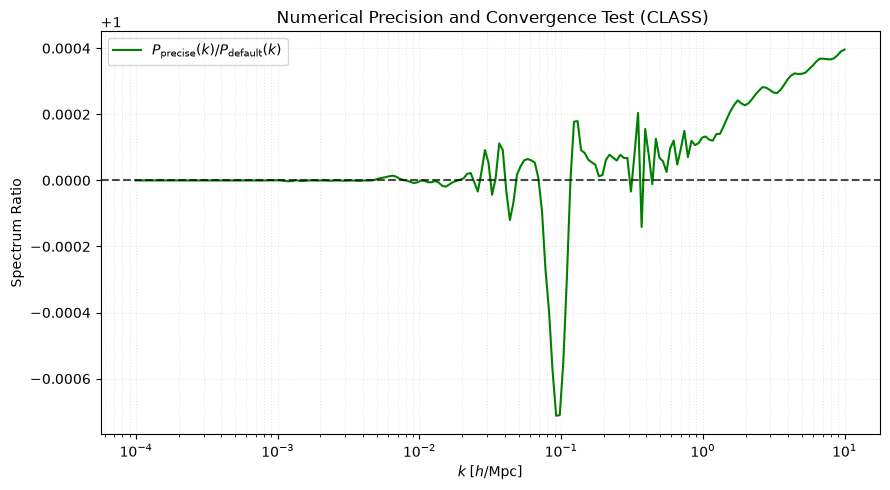

In [30]:
plt.figure(figsize=(9, 5))

plt.plot( k_h, precision_ratio, 'g-', label = r'$P_{\mathrm{precise}}(k) / P_{\mathrm{default}}(k)$' )
plt.axhline( 1.0, color = 'k', linestyle = '--', alpha = 0.7 )

plt.xscale( 'log' )
plt.xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
plt.ylabel( r'Spectrum Ratio' )
plt.title(' Numerical Precision and Convergence Test (CLASS)' )

plt.grid( True, which = "both", ls = ":", alpha = 0.3 )
plt.legend()


plt.tight_layout()
plt.savefig( f"{output_base}_precision_test.png", dpi = 300, bbox_inches = "tight" )
plt.show()


cosmo_def.struct_cleanup()
cosmo_def.empty()

cosmo_prec.struct_cleanup()
cosmo_prec.empty()

### Independent Solver Comparison (CLASS vs CAMB)

In [34]:
cosmo_c = Class()
cosmo_c.set({
    'h': h, 'omega_b': Omega_b * ( h ** 2 ), 'omega_cdm': Omega_cdm * ( h ** 2 ), 'A_s': A_s, 'n_s': n_s, 'k_pivot': k_pivot,
    'output': 'mPk', 'z_pk': z_output, 'non linear': 'none','P_k_max_h/Mpc': k_max
    })

cosmo_c.compute()

pk_class_compare = np.array( [ cosmo_c.pk_lin( k_val, z_output ) * ( h ** 3 ) for k_val in k_mpc ] )

In [35]:
pars = camb.CAMBparams()
pars.set_cosmology(
    H0 = 100.0 * h, ombh2 = Omega_b * ( h ** 2 ), omch2 = Omega_cdm * ( h ** 2 ), omk = 0.0, standard_neutrino_neff = 3.046
    )
pars.InitPower.set_params(
    As = A_s, ns = n_s, pivot_scalar = k_pivot
    )
pars.set_matter_power(
    redshifts = [ z_output ] , kmax = k_max
    )

pars.NonLinear = camb.model.NonLinear_none

results                  = camb.get_results( pars )
kh_camb, z_camb, pk_camb = results.get_matter_power_spectrum(
    minkh = k_min, maxkh = k_max, npoints = k_num_points
)

pk_camb_interp = np.interp(k_h, kh_camb, pk_camb[0])

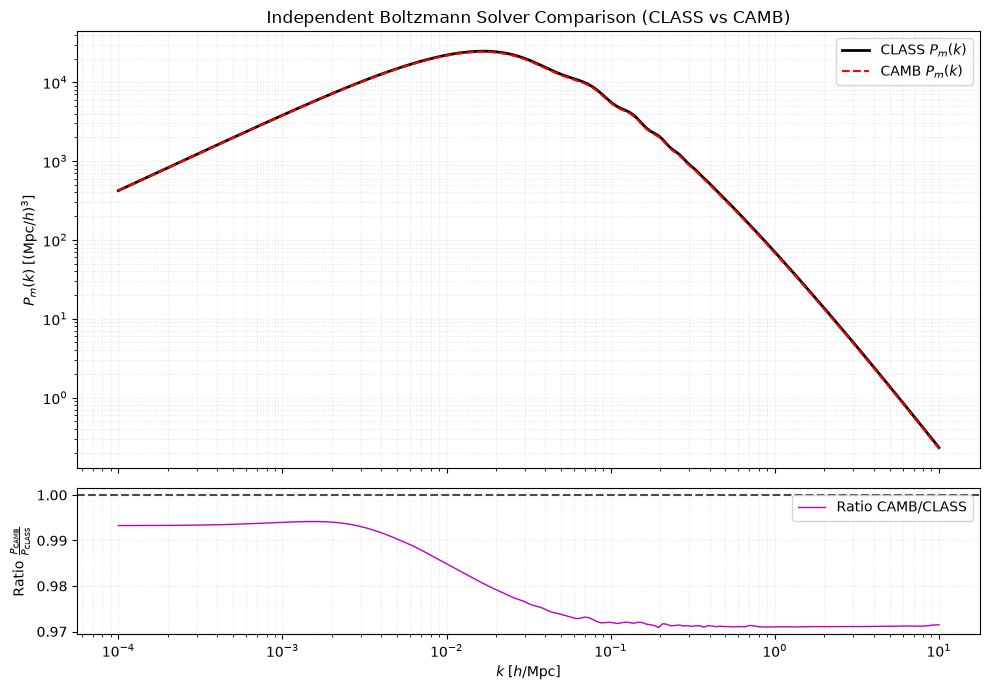

In [36]:
ratio_camb_class = pk_camb_interp / pk_class_compare

fig, axes = plt.subplots( 2, 1, figsize = ( 10, 7 ), sharex = True, gridspec_kw = {'height_ratios': [ 3, 1 ]} )

axes[0].plot( k_h, pk_class_compare, 'k-',  lw = 2,   label = r'CLASS $P_m(k)$' )
axes[0].plot( k_h, pk_camb_interp,   'r--', lw = 1.5, label = r'CAMB $P_m(k)$' )
axes[0].set_xscale( 'log' )
axes[0].set_yscale( 'log' )
axes[0].set_ylabel( r'$P_m(k) \; [(\mathrm{Mpc}/h)^3]$' )
axes[0].set_title( 'Independent Boltzmann Solver Comparison (CLASS vs CAMB)' )
axes[0].grid( True, which = "both", ls = ":", alpha = 0.3)
axes[0].legend( )

axes[1].plot( k_h, ratio_camb_class, 'm-', lw = 1.0, label = r'Ratio $\mathrm{CAMB} / \mathrm{CLASS}$' )
axes[1].axhline( 1.0, color = 'k', linestyle = '--', alpha = 0.7 )
axes[1].set_xscale( 'log' )
axes[1].set_xlabel( r'$k \; [h/\mathrm{Mpc}]$' )
axes[1].set_ylabel( r'Ratio $\frac{P_{\mathrm{CAMB}}}{P_{\mathrm{CLASS}}}$' )
axes[1].grid( True, which = "both", ls = ":", alpha = 0.3 )
axes[1].legend()

plt.tight_layout()
plt.savefig( f"{output_base}_class_vs_camb.png", dpi = 300, bbox_inches = "tight" )
plt.show()

cosmo_c.struct_cleanup()
cosmo_c.empty()

### Supplementary Check A

In [37]:
k_val   = 1.0 
tau_max = 20.0

tau_eval = np.linspace( 1e-3, tau_max, 400 )
exact_j0 = spherical_jn( 0, k_val * tau_eval )

tau_l4, y_l4 = validator.solve_free_streaming_hierarchy(
    k = k_val, l_max = 4, tau_max = tau_max, closure_type = 'zero'
)

tau_l15, y_l15 = validator.solve_free_streaming_hierarchy(
    k = k_val, l_max = 15, tau_max = tau_max, closure_type = 'zero'
)

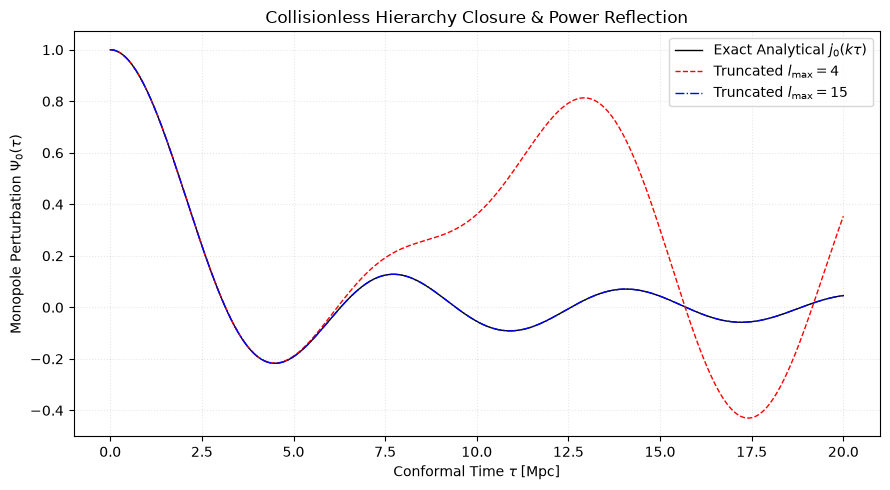

In [38]:
plt.figure( figsize = ( 9, 5 ) )

plt.plot( tau_eval, exact_j0,   'k-', lw = 1.0, label = r'Exact Analytical $j_0(k\tau)$' )
plt.plot( tau_l4, y_l4[ 0 ],   'r--', lw = 1.0, label = r'Truncated $l_{\mathrm{max}}=4$' )
plt.plot( tau_l15, y_l15[ 0 ], 'b-.', lw = 1.0, label = r'Truncated $l_{\mathrm{max}}=15$' )

plt.xlabel( r'Conformal Time $\tau \; [\mathrm{Mpc}]$' )
plt.ylabel( r'Monopole Perturbation $\Psi_0(\tau)$' )
plt.title( 'Collisionless Hierarchy Closure & Power Reflection' )

plt.grid( True, which = 'both', ls=':', alpha = 0.3 )
plt.legend()

plt.tight_layout()

plt.savefig(f'{output_base}_hierarchy_closure.png', dpi = 300, bbox_inches = 'tight')
plt.show()

### Supplementary Check B 

In [39]:
y_vals, phi_vals = validator.solve_superhorizon_potencial( y_init = y_i, y_final = y_f )

phi_i_val = phi_vals[ 0 ]
phi_f_val = phi_vals[ - 1 ]
ratio_val = phi_f_val / phi_i_val

print("=" * 65)
print("Supplementary Check B Validation:")
print(f"Phi Initial (y = {float(y_i):.1e}): {phi_i_val:.6f} | Expected: -0.666662")
print(f"Phi Final   (y = {float(y_f):.1e}): {phi_f_val:.6f} | Expected: -0.600000")
print(f"Ratio Phi_m / Phi_r:        {ratio_val:.6f} | Expected:  0.900000")
print("=" * 65)


Supplementary Check B Validation:
Phi Initial (y = 1.0e-04): -0.666662 | Expected: -0.666662
Phi Final   (y = 1.0e+03): -0.600133 | Expected: -0.600000
Ratio Phi_m / Phi_r:        0.900205 | Expected:  0.900000


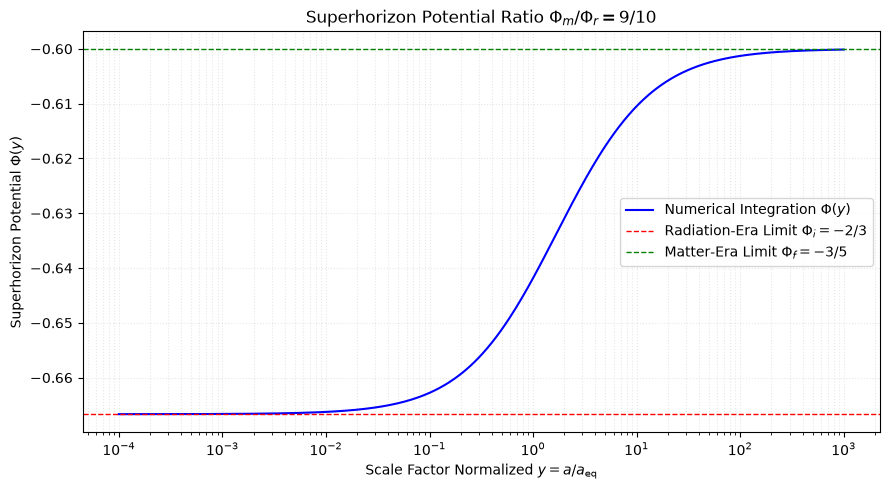

In [40]:
plt.figure( figsize = ( 9, 5 ) )

plt.semilogx( y_vals, phi_vals, 'b-', label = r'Numerical Integration $\Phi(y)$' )
plt.axhline( -2.0/3.0, color = 'r', linestyle = '--', lw = 1.0, label = r'Radiation-Era Limit $\Phi_i = -2/3$' )
plt.axhline( -3.0/5.0, color = 'g', linestyle = '--', lw = 1.0, label = r'Matter-Era Limit $\Phi_f = -3/5$' )

plt.xlabel( r'Scale Factor Normalized $y = a / a_{\mathrm{eq}}$' )
plt.ylabel( r'Superhorizon Potential $\Phi(y)$' )

plt.title( r'Superhorizon Potential Ratio $\Phi_m / \Phi_r = 9/10$' )
plt.grid( True, which = "both", ls = ":", alpha = 0.3 )
plt.legend()

plt.tight_layout()
plt.savefig(f"{output_base}_superhorizon_potential.png", dpi = 300, bbox_inches = "tight" )
plt.show()